In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, GlobalAveragePooling2D, Dense, Dropout, BatchNormalization, MaxPooling2D, Reshape, Multiply
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping
from tensorflow.keras.applications import VGG16, VGG19, DenseNet121, ResNet50, MobileNet, InceptionV3, Xception
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import seaborn as sns

2026-11-05 12:56:45.190503: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793883405.436196      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793883405.502072      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793883406.072078      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793883406.072147      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793883406.072150      23 computation_placer.cc:177] computation placer alr

In [2]:
# Parameters
input_shape = (224, 224, 3)
num_classes = 5
lr = 1e-5
bs = 32
ep = 30

# Define paths
base_dir = "/kaggle/input/datasets/prahladmehandiratta/cervical-cancer-largest-dataset-sipakmed"
cropped_dirs = {
    cls: os.path.join(base_dir, cls, cls, "CROPPED")
    for cls in ["im_Dyskeratotic", "im_Metaplastic", "im_Koilocytotic", "im_Parabasal", "im_Superficial-Intermediate"]
}
uncropped_dirs = {
    cls: os.path.join(base_dir, cls, cls)
    for cls in ["im_Dyskeratotic", "im_Metaplastic", "im_Koilocytotic", "im_Parabasal", "im_Superficial-Intermediate"]
}

In [3]:
import re

def load_images_from_directory(directory, target_size=(224, 224)):
    images, filenames = [], []
    for filename in sorted(os.listdir(directory)):
        img = cv2.imread(os.path.join(directory, filename))
        if img is not None:
            img = cv2.resize(img, target_size)
            images.append(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
            filenames.append(filename)
    return np.array(images), filenames

cropped_images, cropped_labels, cropped_groups = {}, {}, {}
for cls, dir_path in cropped_dirs.items():
    images, filenames = load_images_from_directory(dir_path)
    cropped_images[cls] = images
    cropped_labels[cls] = np.full(len(images), cls)
    cropped_groups[cls] = np.array([f"{cls}_{re.split(r'[_.]', fn)[0]}" for fn in filenames])

X_cropped = np.concatenate(list(cropped_images.values()))
y_cropped = np.concatenate(list(cropped_labels.values()))
groups    = np.concatenate(list(cropped_groups.values()))

label_to_index = {cls: idx for idx, cls in enumerate(cropped_dirs.keys())}
y_cropped = np.array([label_to_index[label] for label in y_cropped])
y_cropped = to_categorical(y_cropped, num_classes=5)

def group_split_per_class(y_int, groups, fractions=(0.80, 0.15, 0.05)):
    rng = np.random.RandomState(42)
    split_of_group = {}
    for c in np.unique(y_int):
        idx = np.where(y_int == c)[0]
        ugroups = np.unique(groups[idx])
        rng.shuffle(ugroups)
        sizes = {g: np.sum(groups[idx] == g) for g in ugroups}
        targets = [f * len(idx) for f in fractions]
        filled = [0, 0, 0]
        for g in ugroups:
            s = int(np.argmax([(targets[k] - filled[k]) / targets[k] for k in range(3)]))
            split_of_group[g] = s
            filled[s] += sizes[g]
    return np.array([split_of_group[g] for g in groups])

split_id = group_split_per_class(y_cropped.argmax(axis=1), groups)

X_train, y_train = X_cropped[split_id == 0], y_cropped[split_id == 0]
X_val,   y_val   = X_cropped[split_id == 1], y_cropped[split_id == 1]
X_test,  y_test  = X_cropped[split_id == 2], y_cropped[split_id == 2]

g_train, g_val, g_test = (set(groups[split_id == k]) for k in range(3))
assert not (g_train & g_val) and not (g_train & g_test) and not (g_val & g_test), "DATA LEAK!"
print(f"Train: {len(X_train)} imgs / {len(g_train)} groups")
print(f"Val  : {len(X_val)} imgs / {len(g_val)} groups")
print(f"Test : {len(X_test)} imgs / {len(g_test)} groups")

Train: 3192 imgs / 758 groups
Val  : 630 imgs / 148 groups
Test : 227 imgs / 60 groups


In [4]:
# Data augmentation
datagen = ImageDataGenerator(
    rotation_range=20,         # Random rotation up to 20 degrees
    zoom_range=[0.8, 1.0],     # Zoom out by up to 20%
    brightness_range=[0.9, 1.1],  
    horizontal_flip=True,
    vertical_flip=True,
    preprocessing_function=lambda x: tf.image.adjust_contrast(x, np.random.uniform(0.9, 1.1)),  # Custom contrast adjustment
    fill_mode='nearest'
)

# Fit the generator to the training data
datagen.fit(X_train)

In [5]:
base_model = MobileNet(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Add the minimal classification head
x = base_model.output
x = GlobalAveragePooling2D()(x)                  # Reduces feature maps to a vector
output_layer = Dense(5, activation='softmax')(x)  # 5 classes

# Create the full model
model = Model(inputs=base_model.input, outputs=output_layer)
model.compile(optimizer=Adam(learning_rate=lr), loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

I0000 00:00:1793884422.033782      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793884422.040657      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 112, 112, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_bn (BatchNormalization)   │ (None, 112, 112, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_relu (ReLU)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1 (DepthwiseConv2D)     │ (None, 112, 112, 32)   │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1_bn                    │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1_relu (ReLU)           │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1 (Conv2D)              │ (None, 112, 112, 64)   │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1_bn                    │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1_relu (ReLU)           │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pad_2 (ZeroPadding2D)      │ (None, 113, 113, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2 (DepthwiseConv2D)     │ (None, 56, 56, 64)     │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2_bn                    │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2_relu (ReLU)           │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2 (Conv2D)              │ (None, 56, 56, 128)    │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2_relu (ReLU)           │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3 (DepthwiseConv2D)     │ (None, 56, 56, 128)    │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3_relu (ReLU)           │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_3 (Conv2D)              │ (None, 56, 56, 128)    │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_3_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 3,233,989 (12.34 MB)

 Trainable params: 3,212,101 (12.25 MB)

 Non-trainable params: 21,888 (85.50 KB)

In [6]:
class_counts = np.sum(y_train, axis=0)           
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(num_classes),
    y=np.argmax(y_train, axis=1)
)

class_weight_dict = dict(enumerate(class_weights))

print("Class counts (train):", class_counts.astype(int))
print("Class weights:", class_weight_dict)

Class counts (train): [637 627 643 624 661]
Class weights: {0: np.float64(1.0021978021978022), 1: np.float64(1.018181818181818), 2: np.float64(0.9928460342146189), 3: np.float64(1.023076923076923), 4: np.float64(0.9658093797276853)}


In [7]:
history = model.fit(
    datagen.flow(X_train, y_train, batch_size=bs),
    validation_data=(X_val, y_val),
    epochs=ep,
    batch_size=bs,
    class_weight=class_weight_dict
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30


I0000 00:00:1793884439.753591      69 service.cc:152] XLA service 0x780664002e20 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793884439.753627      69 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1793884439.753631      69 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1793884442.203214      69 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-11-05 13:14:11.470507: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 13:14:11.608974: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1793884464.008959      69 device_co

 68/100 ━━━━━━━━━━━━━━━━━━━━ 15s 500ms/step - accuracy: 0.3339 - loss: 1.5984

2026-11-05 13:15:08.759147: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 13:15:08.896836: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 716ms/step - accuracy: 0.3954 - loss: 1.4600

2026-11-05 13:15:47.939000: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 13:15:48.077476: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


100/100 ━━━━━━━━━━━━━━━━━━━━ 123s 844ms/step - accuracy: 0.3971 - loss: 1.4563 - val_accuracy: 0.2889 - val_loss: 2.1026
Epoch 2/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 51s 508ms/step - accuracy: 0.7944 - loss: 0.5970 - val_accuracy: 0.8000 - val_loss: 0.5412
Epoch 3/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 51s 510ms/step - accuracy: 0.8493 - loss: 0.4312 - val_accuracy: 0.8825 - val_loss: 0.3564
Epoch 4/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 52s 517ms/step - accuracy: 0.8629 - loss: 0.3782 - val_accuracy: 0.8857 - val_loss: 0.3283
Epoch 5/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 51s 512ms/step - accuracy: 0.8893 - loss: 0.3205 - val_accuracy: 0.8889 - val_loss: 0.3024
Epoch 6/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 51s 512ms/step - accuracy: 0.9064 - loss: 0.2652 - val_accuracy: 0.8968 - val_loss: 0.2888
Epoch 7/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 51s 506ms/step - accuracy: 0.9108 - loss: 0.2437 - val_accuracy: 0.9032 - val_loss: 0.2679
Epoch 8/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 51s 514ms/step - accuracy: 0.9278 - loss: 0.2320 - va

6/8 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.8518 - loss: 0.3095

2026-11-05 13:40:42.762067: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-05 13:40:42.901024: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


8/8 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.8688 - loss: 0.2803
Test Loss: 0.220816
Test Accuracy: 0.903084


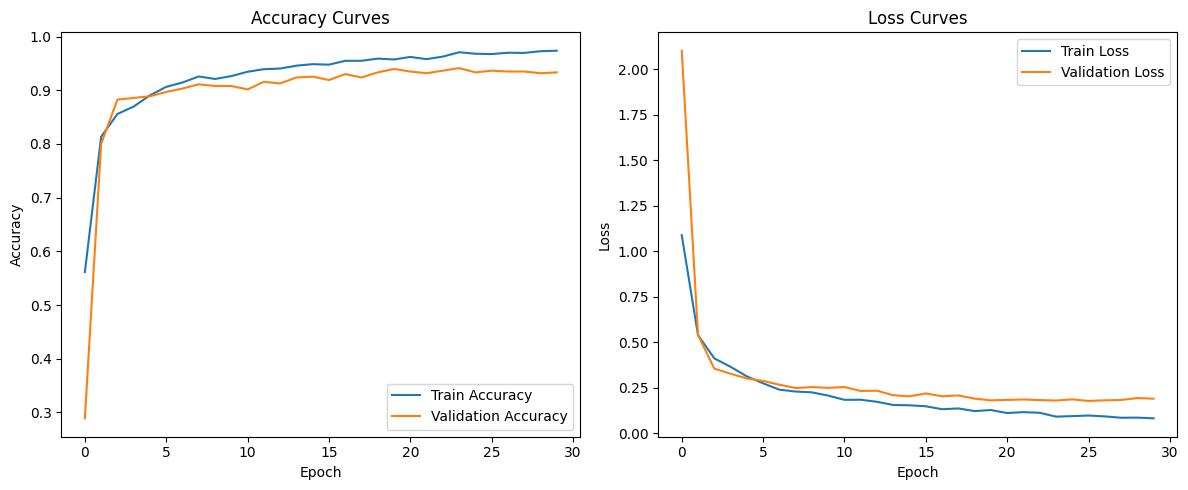

8/8 ━━━━━━━━━━━━━━━━━━━━ 6s 451ms/step
Classification Report (Test Set):
                             precision    recall  f1-score   support

            im_Dyskeratotic   1.000000  0.822222  0.902439        45
             im_Metaplastic   0.894737  0.829268  0.860759        41
            im_Koilocytotic   0.828125  0.898305  0.861789        59
               im_Parabasal   1.000000  0.974359  0.987013        39
im_Superficial-Intermediate   0.860000  1.000000  0.924731        43

                   accuracy                       0.903084       227
                  macro avg   0.916572  0.904831  0.907346       227
               weighted avg   0.909796  0.903084  0.903099       227



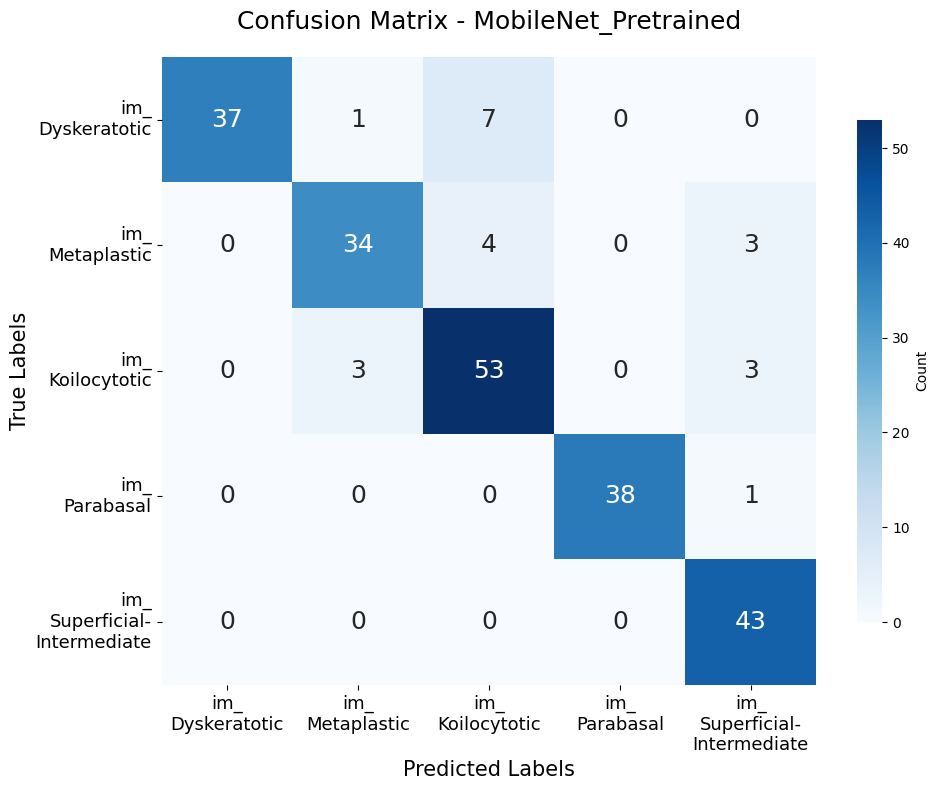

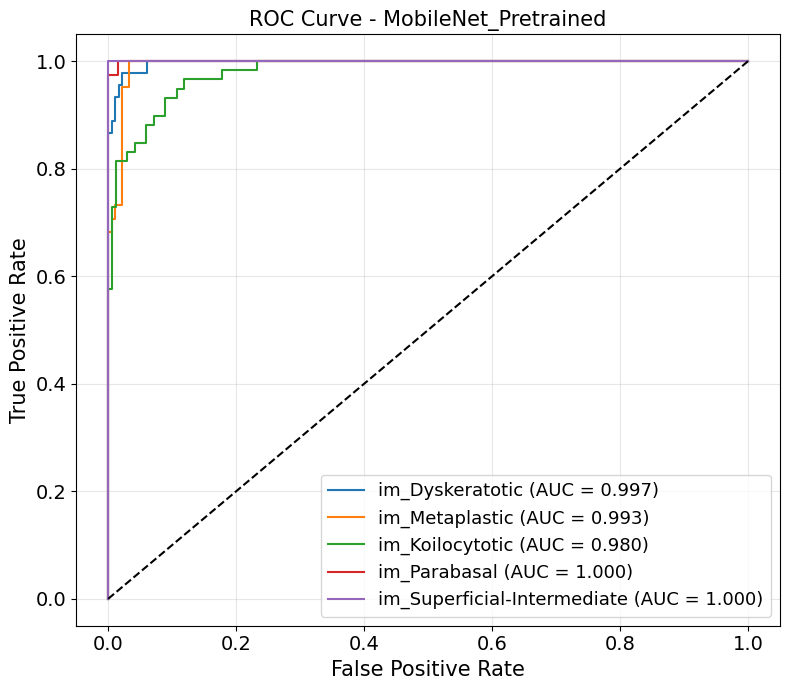

Model saved successfully.


In [8]:
# ===============================
# Final Test Evaluation
# ===============================
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)
print(f"Test Loss: {test_loss:.6f}")
print(f"Test Accuracy: {test_accuracy:.6f}")


# ===============================
# Training Curves (Train + Val)
# ===============================
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Curves')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Curves')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


# ===============================
# Predictions on TEST set only
# ===============================
y_pred_test = model.predict(X_test, verbose=1)

y_pred_classes = np.argmax(y_pred_test, axis=1)
y_true_classes = np.argmax(y_test, axis=1)


# ===============================
# Classification Report (TEST)
# ===============================
print("Classification Report (Test Set):")
print(
    classification_report(
        y_true_classes,
        y_pred_classes,
        target_names=list(cropped_dirs.keys()),
        digits=6        
    )
)


# ===============================
# Confusion Matrix (TEST)
# ===============================
class_names = list(label_to_index.keys())
class_names_wrapped = [
    name.replace('_', '_\n').replace('-', '-\n')
    for name in class_names
]
conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

plt.figure(figsize=(10, 8))           

sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names_wrapped,
    yticklabels=class_names_wrapped,
    annot_kws={"size": 18},           
    cbar_kws={"label": "Count", "shrink": 0.8}
)

# Font size adjustments
plt.xticks(fontsize=13, rotation=0, ha='center')   
plt.yticks(fontsize=13, rotation=0)

plt.xlabel("Predicted Labels", fontsize=15)
plt.ylabel("True Labels",      fontsize=15)
plt.title("Confusion Matrix - MobileNet_Pretrained", fontsize=18, pad=20)

plt.tight_layout()
plt.show()


# ===============================
# ROC Curve & AUC (TEST)
# ===============================
num_classes = y_test.shape[1]
fpr = {}
tpr = {}
roc_auc = {}

class_names = list(label_to_index.keys())          

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test[:, i], y_pred_test[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(8, 7))   

for i in range(num_classes):
    plt.plot(
        fpr[i],
        tpr[i],
        label=f'{class_names[i]} (AUC = {roc_auc[i]:.3f})'   
    )

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate',      fontsize=15)
plt.ylabel('True Positive Rate',      fontsize=15)
plt.title('ROC Curve - MobileNet_Pretrained',      fontsize=15)
plt.legend(loc='lower right', fontsize=13)
plt.grid(True, alpha=0.3)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.tight_layout()
plt.show()


# ===============================
# Save Model
# ===============================
model.save("cervical_cancer_model.h5")
print("Model saved successfully.")